In [1]:
#!pip install scikit-fuzzy

In [1]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np


### **Entrada de datos (en contexto con Nivel 2 y 3 del modelo JDL)**

#### Nivel de Stock Actual (Nivel 2 - Valoración de la situación): Estado actual del inventario, categorizado como bajo, medio o alto. (NS)
#### Impacto de las promociones (Nivel 3 - Valoración del impacto): Se evalúa el efecto de las promociones actuales en la demanda futura, clasificándolo como bajo, medio o alto. (IP)
#### Capacidad de Reabastecimiento (Nivel 3 - Valoración del impacto): Tiempo y facilidad con los que se puede reponer el inventario, teniendo en cuenta la cadena de suministro y la logística. (CR)
#### Eficiencia de la cadena de suministro (Nivel 2 - Valoración de la situación): Se categoriza como ineficiente, moderada o eficiente, dependiendo del tiempo de respuesta para reabastecer el inventario.(ES)

In [49]:
NS = ctrl.Antecedent(np.arange(0, 101, 1), 'Nivel de stock')
IP = ctrl.Antecedent(np.arange(0, 101, 1), 'Impacto_promocion')
CR = ctrl.Antecedent(np.arange(0, 101, 1), 'Capacidad de reabastecimiento')
ES = ctrl.Antecedent(np.arange(0, 101, 1), 'Eficiencia cadena de suministro')

### **Variables de salida (Consecuentes)**

#### Acción de ajuste de inventario: Se determina si se debe reducir significativamente, reducir ligeramente, mantener, aumentar ligeramente o aumentar significativamente el inventario. (AI)

In [50]:
AI = ctrl.Consequent(np.arange(-100, 101, 1), 'Ajuste inventario')

### **Conjuntos difusos (funciones de membresia)**

In [51]:
# Nivel de stock
NS['bajo'] = fuzz.trapmf(NS.universe, [0, 0, 20, 30])
NS['medio'] = fuzz.trapmf(NS.universe, [20, 30, 65, 80])
NS['alto'] = fuzz.trapmf(NS.universe, [65, 80, 100, 100])


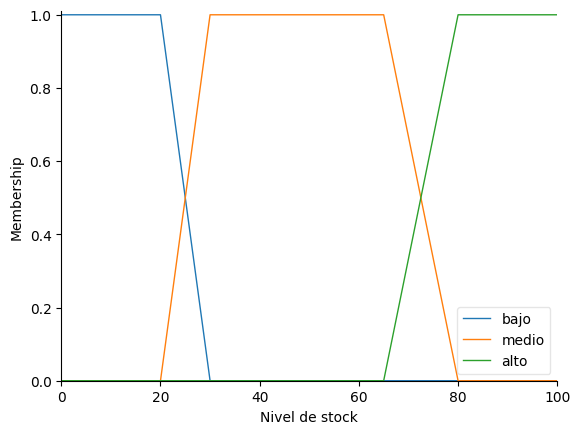

In [52]:
NS.view()

In [53]:
# Impacto promocion
IP['bajo'] = fuzz.trapmf(IP.universe, [0, 0, 10,25])
IP['medio'] = fuzz.trimf(IP.universe, [20, 40, 60])
IP['alto'] = fuzz.trapmf(IP.universe, [50, 70, 100, 100])


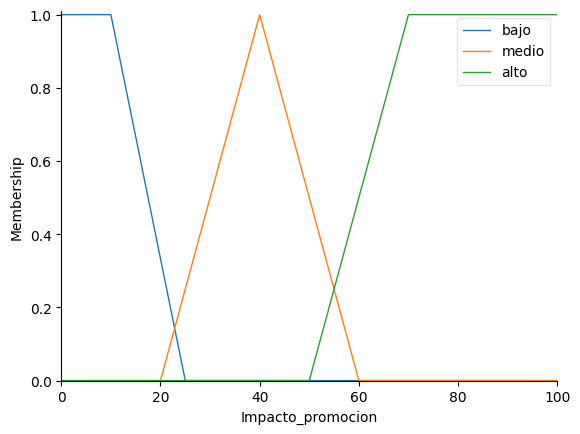

In [54]:
IP.view()

In [55]:
# Capacidad de reabastecimiento
CR['bajo'] = fuzz.trimf(CR.universe, [0, 0, 30])
CR['medio'] = fuzz.trimf(CR.universe, [20, 50, 80])
CR['alto'] = fuzz.trimf(CR.universe, [70, 100, 100])

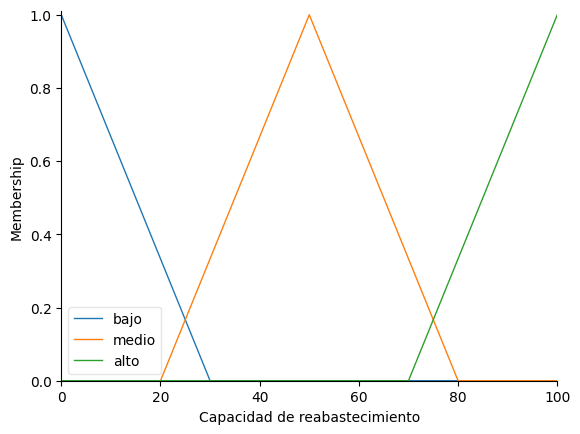

In [56]:
CR.view()

In [57]:
# Eficiencia cadena de suministro

ES['bajo'] = fuzz.trapmf(ES.universe, [0, 0, 10,25])
ES['medio'] = fuzz.trimf(ES.universe, [20, 40, 60])
ES['alto'] = fuzz.trapmf(ES.universe, [50, 70, 100, 100])

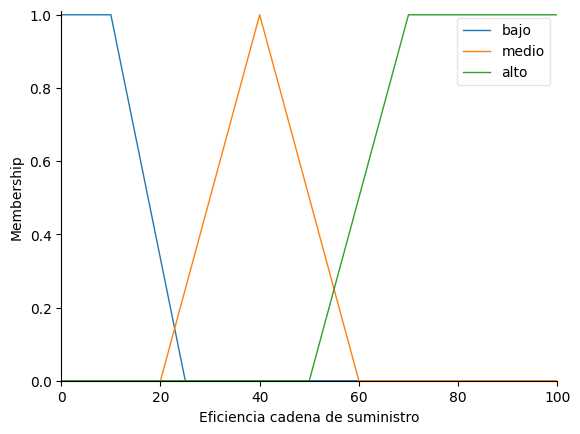

In [58]:
ES.view()

In [59]:
# Escala de tiempo real en segundos para las funciones de membresía de Tiempo de Semáforo 
AI['reducir'] = fuzz.trimf(AI.universe, [-50, -25, 0])
AI['mantener'] = fuzz.trimf(AI.universe, [-10, 0, 10])
AI['aumentar'] = fuzz.trimf(AI.universe, [0, 25, 50])


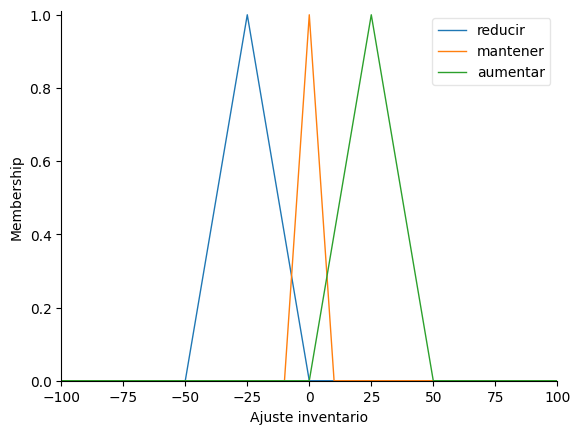

In [60]:
AI.view()

## Crear reglas

In [61]:
# Definición de las reglas de inferencia para el sistema FIS
rules = []

# Iterar a través de todas las combinaciones de los estados de las variables
for ns_level in ['bajo', 'medio', 'alto']:
    for ip_level in ['bajo', 'medio', 'alto']:
        for cr_level in ['bajo', 'medio', 'alto']:
            for es_level in ['bajo', 'medio', 'alto']:
                # Definir la lógica de las reglas basada en los niveles de las variables
                if ip_level == 'alto' or ns_level == 'bajo':
                    inv_output = 'aumentar'  # Aumentar el inventario debido a alta promoción o stock bajo
                elif cr_level == 'bajo' and (ip_level == 'medio' or ns_level == 'medio'):
                    inv_output = 'mantener'  # Mantener inventario si la capacidad de reabastecimiento es limitada
                elif ns_level == 'alto' and ip_level == 'bajo' and es_level != 'bajo':
                    inv_output = 'reducir'  # Reducir inventario si el impacto de la promoción es bajo y la cadena es eficiente
                else:
                    inv_output = 'mantener'  # Mantener inventario en condiciones estándares

                # Crear y añadir la regla
                rule = ctrl.Rule(NS[ns_level] & IP[ip_level] & CR[cr_level] & ES[es_level], AI[inv_output])
                rules.append(rule)


In [62]:
cont=0
for rule in rules:
    cont+=1
    print(rule)
print(cont)

IF ((Nivel de stock[bajo] AND Impacto_promocion[bajo]) AND Capacidad de reabastecimiento[bajo]) AND Eficiencia cadena de suministro[bajo] THEN Ajuste inventario[aumentar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Nivel de stock[bajo] AND Impacto_promocion[bajo]) AND Capacidad de reabastecimiento[bajo]) AND Eficiencia cadena de suministro[medio] THEN Ajuste inventario[aumentar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Nivel de stock[bajo] AND Impacto_promocion[bajo]) AND Capacidad de reabastecimiento[bajo]) AND Eficiencia cadena de suministro[alto] THEN Ajuste inventario[aumentar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Nivel de stock[bajo] AND Impacto_promocion[bajo]) AND Capacidad de reabastecimiento[medio]) AND Eficiencia cadena de suministro[bajo] THEN Ajuste inventario[aumentar]
	AND aggregation function : fmin
	OR aggregation function  : fmax
IF ((Nivel de stock[bajo] AND Impacto_promocion[ba

In [63]:
# Sistema de control y la simulación
ai_ctrl = ctrl.ControlSystem(rules)
ai_sim = ctrl.ControlSystemSimulation(ai_ctrl)

In [88]:
type(ai_sim)

skfuzzy.control.controlsystem.ControlSystemSimulation

In [64]:
# Asignando algunas entradas para probar el sistema
ai_sim.input['Nivel de stock'] = 20  
ai_sim.input['Impacto_promocion'] = 85
ai_sim.input['Capacidad de reabastecimiento'] = 50
ai_sim.input['Eficiencia cadena de suministro'] = 80



In [65]:
# Computando el resultado
ai_sim.compute()

El Ajuste del inventario sugerido es de: 24.999999999999996


f:\fusion_datos\codigo_taller2\fis_env\lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


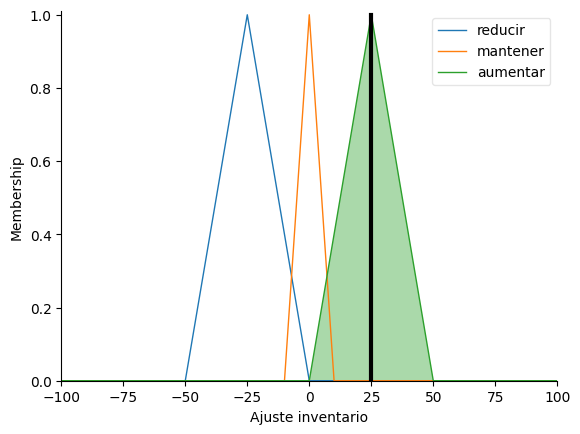

In [66]:
# Imprimiendo el nivel de desempeño resultante
output_ai = ai_sim.output['Ajuste inventario']
print(f"El Ajuste del inventario sugerido es de: {output_ai}")
AI.view(sim=ai_sim)